In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import etunc.config as cfg

In [2]:
RUNS = pd.read_csv(cfg.RUNS_CSV)
RUNS

,run_id,prep_id,run_file,created_utc,git_commit,git_branch,time_slice,target_res,families,bin_variable,area_weighted,n_ybins,n_xbins,settings_json
0,r183a58a,p2abea0a,default,2026-11-09 21:28:11,8b0c76d,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,False,15,15,"{""binning"":{""area_weighted"":false,""bin_variabl..."
1,r78ee6dc,p2abea0a,config/runs/bins10.yml,2026-11-09 23:24:19,7ef092c,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,False,10,10,"{""binning"":{""area_weighted"":false,""bin_variabl..."
2,r5b27e56,p2abea0a,config/runs/aw_bins10.yml,2026-11-10 00:08:02,7ef092c,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,True,10,10,"{""binning"":{""area_weighted"":true,""bin_variable..."
3,r67357a7,p2abea0a,config/runs/bins20.yml,2026-11-10 00:13:13,7ef092c,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,False,20,20,"{""binning"":{""area_weighted"":false,""bin_variabl..."
4,r1166e5e,p2abea0a,config/runs/aw_bins20.yml,2026-11-10 00:19:30,7ef092c,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,True,20,20,"{""binning"":{""area_weighted"":true,""bin_variable..."
5,r59533f4,p2abea0a,config/runs/aw_bins15.yml,2026-11-10 00:25:14,7ef092c,run-config,2001-01-2014-12,1.0,obs era5 cmip fppe ippe lens trendy_s3,et,True,15,15,"{""binning"":{""area_weighted"":true,""bin_variable..."


# Inputs

In [2]:
OLD_ROOTDIR = Path("/glade/work/bbuchovecky/et_unc_legacy")
TIME_PERIOD = "200101-201412"

In [ ]:
PREP_ID = "p2abea0a"

In [12]:
FAMILIES = ("cmip", "obs", "fppe", "ippe", "era5", "trendy_s3", "plumber")

for f in FAMILIES:
    print(f)
    oin = xr.open_dataset(OLD_ROOTDIR / "proc" / f / "inputs" / TIME_PERIOD / f"{f}.inputs.1deg.{TIME_PERIOD}.nc")
    nin = xr.open_dataset(cfg.inputs_path(f, PREP_ID))
    assert [v in list(nin.data_vars) for v in list(oin.data_vars)]
    if len(nin.data_vars) < len(oin.data_vars):
        print(set(oin.data_vars) - set(nin.data_vars))
    elif len(oin.data_vars) < len(nin.data_vars):
        print(set(nin.data_vars) - set(oin.data_vars))
    for v in oin.data_vars:
        assert nin[v].shape == oin[v].shape
        x = nin[v].values.flatten() - oin[v].values.flatten()
        print("  ", v, ": max diff =", abs(x[~np.isnan(x)]).max())
    del oin, nin

cmip
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
   et_pr : max diff = 0.0
obs
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
   et_pr : max diff = 0.0
fppe
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
   et_pr : max diff = 0.0
ippe
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
   et_pr : max diff = 0.0
era5
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
   et_pr : max diff = 0.0
trendy_s3
{'et_pr'}
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 0.0
plumber
{'et_pr'}
   et : max diff = 0.0
   lai : max diff = 0.0
   pr : max diff = 0.0
   rn : max diff = 0.0
   ai : max diff = 

# Outputs

In [3]:
BIN_VARIABLE = "et"

OLD_ROOTDIR = Path("/glade/work/bbuchovecky/et_unc_legacy")
TIME_PERIOD = "200101-201412"
BINS = "lai15_ai15"

KIND = "pooled_all"

RUN_ID = "r183a58a"

In [7]:
FAMILIES = ("cmip", "obs", "fppe", "ippe", "era5", "trendy_s3", "plumber")

for f in FAMILIES:
    print(f)
    oin = xr.open_dataset(OLD_ROOTDIR / "proc" / f / "qbin" / TIME_PERIOD / BINS / f"{f}.{BIN_VARIABLE}.qbin_{KIND}.{BINS}.1deg.{TIME_PERIOD}.nc")
    nin = xr.open_dataset(cfg.output_dir(cfg.PROC_ROOT, f, "qbin", RUN_ID) / f"{f}.{BIN_VARIABLE}.qbin_{KIND}.{RUN_ID}.nc")
    assert [v in list(nin.data_vars) for v in list(oin.data_vars)]
    if len(nin.data_vars) < len(oin.data_vars):
        print("  oin>nin:", set(oin.data_vars) - set(nin.data_vars))
    elif len(oin.data_vars) < len(nin.data_vars):
        print("  oin>nin:", set(nin.data_vars) - set(oin.data_vars))
    for v in oin.data_vars:
        assert nin[v].shape == oin[v].shape
        x = nin[v].values.flatten() - oin[v].values.flatten()
        print("  ", v, ": max diff =", abs(x[~np.isnan(x)]).max())
    del oin, nin

cmip
   et : max diff = 778.2803906988926
obs
   et : max diff = 367.1997077373358
fppe
   et : max diff = 474.83382145007585
ippe
   et : max diff = 741.7164186972294
era5
   et : max diff = 166.90248265481915
trendy_s3
   et : max diff = 736.7781226323416
plumber
   et : max diff = 59.4529459883249


In [9]:
f = "cmip"

print(f)
oin = xr.open_dataset(OLD_ROOTDIR / "proc" / f / "qbin" / TIME_PERIOD / BINS / f"{f}.{BIN_VARIABLE}.qbin_{KIND}.{BINS}.1deg.{TIME_PERIOD}.nc")
nin = xr.open_dataset(cfg.output_dir(cfg.PROC_ROOT, f, "qbin", RUN_ID) / f"{f}.{BIN_VARIABLE}.qbin_{KIND}.{RUN_ID}.nc")
assert [v in list(nin.data_vars) for v in list(oin.data_vars)]
if len(nin.data_vars) < len(oin.data_vars):
    print("  oin>nin:", set(oin.data_vars) - set(nin.data_vars))
elif len(oin.data_vars) < len(nin.data_vars):
    print("  oin>nin:", set(nin.data_vars) - set(oin.data_vars))
for v in oin.data_vars:
    assert nin[v].shape == oin[v].shape
    x = nin[v].values.flatten() - oin[v].values.flatten()
    print("  ", v, ": max diff =", abs(x[~np.isnan(x)]).max())

cmip
   et : max diff = 778.2803906988926


In [31]:
oin

<xarray.Dataset> Size: 566kB
Dimensions:       (member: 44, stats: 7, y_bin: 15, x_bin: 15)
Coordinates: (12/16)
  * member        (member) <U25 4kB 'ACCESS-ESM1-5.r1i1p1f1' ... 'UKESM1-0-LL...
    member_id     (member) <U10 2kB ...
    source        (member) <U16 3kB ...
  * stats         (stats) <U9 252B 'mean' 'var_pop' ... 'sum_w' 'n_eff'
  * y_bin         (y_bin) int64 120B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
    y_bin_lower   (y_bin) float64 120B ...
    ...            ...
    x_bin_lower   (x_bin) float64 120B ...
    x_bin_upper   (x_bin) float64 120B ...
    x_bin_center  (x_bin) float64 120B ...
    x_bin_label   (x_bin) <U8 480B ...
    ltype         int64 8B ...
    landunit      <U40 160B ...
Data variables:
    et            (member, stats, y_bin, x_bin) float64 554kB 18.01 ... 0.0

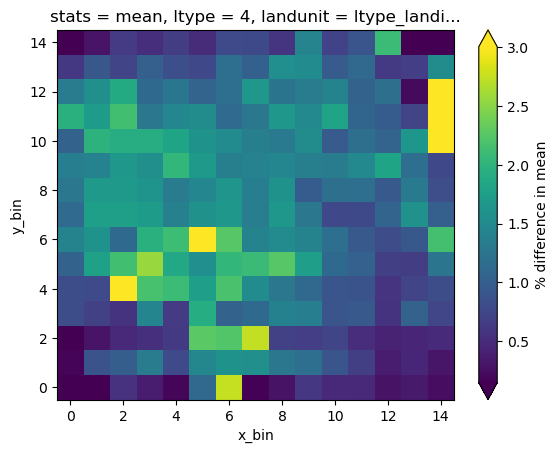

In [44]:
v = "mean"
(
    abs(oin.et.sel(stats=v) - nin.et.sel(stats=v)).mean(dim="member")
    / abs(oin.et.sel(stats=v)).mean(dim="member")
    * 100
).plot(robust=True, cbar_kwargs={"label": f"% difference in {v}"})

The differences come entirely from the **variant weighting** in commit c98a922 ("Weight means and stds across a family by groups of variants", 2026-11-06). The legacy outputs were made on 2026-10-28, before that commit. Nothing in the data or the binning itself changed; only the LAI/AI bin edges moved, so some gridcells now land in a neighbouring bin.

**What's unchanged:**

- **Inputs:** your notebook already shows they're bit-identical.
- **Common area mask:** identical, 10,087 cells, 0 cells differ.
- **Edges of families with one source per group:** `pooled_fppe`, `pooled_ippe`, `pooled_era5` and `pooled_trendy_s3` are bit-identical, and so are their qbin outputs (max |Δmean| = 0, Δcount = 0).

**What changed:** `edges.hierarchical_weights` gained a "group of variants" level. Each family is now split into groups, then sources, then members, so near-duplicate sources count once:

- CMIP6: 44 models become 20 base-model groups (e.g. CESM2 and CESM2-WACCM count once together), so the pooled_cmip edges moved a lot. The LAI edges shifted by up to ~0.17, and the qbin means by up to ~36 W/m².
- Obs: 12 combinations become 10 groups (GLEAMv4.3a/b and PMLv2.2a_MODIS/c are each merged), so the pooled_obs edges moved only at the 3rd decimal. Its qbin means changed by up to ~1 W/m².
- `pooled_all` mixes cmip and obs, so its edges shifted slightly (third-decimal level, up to ~0.03 in LAI). That changes every family's qbin_pooled_all output, including fppe, ippe, era5 and trendy_s3.

**Check:** I recomputed the edges from the current inputs and mask with the group level switched off (each source its own group). That reproduces the legacy `pooled_all`, `pooled_cmip` and `pooled_obs` edges exactly, for both LAI and AI. With the group level on, it reproduces the current edges exactly. So the variant grouping accounts for the whole difference.

Other legacy outputs will also differ for the same reason, beyond the binned values: the obs `et_product_std`, the ensemble spreads, and the decomposition's obs and family pools.

The comparison scripts are in `/glade/derecho/scratch/bbuchovecky/tmp/claude-39176/-glade-u-home-bbuchovecky-projects-et-unc/e53664af-43d3-4276-ba2e-556300746969/scratchpad/` (`cmp.py`, `cmpq.py`, `regen.py`) if you want to add any of them to `check-refactor.ipynb`.